# Topic Modeling with Gensim

We saw the Gensim library before for Word2Vec and GloVE representations. Here we will see some convenient Topic Modeling functions that it provides. We will essentially follow [this tutorial](https://www.youtube.com/watch?v=ZkAFJwi-G98).

In [1]:
!pip install pyLDAvis
!python -m spacy download en_core_web_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 17.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 139.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import matplotlib.pyplot as plt
import gensim
import numpy as np
import spacy

from gensim.models import CoherenceModel, LdaModel, LsiModel, HdpModel
from gensim.corpora import Dictionary

from sklearn.metrics.pairwise import cosine_similarity

import pyLDAvis.gensim

import os, re, operator, warnings
warnings.filterwarnings('ignore')  # Let's not pay heed to them right now
%matplotlib inline

Let's do some text cleaning. We got used to use nltk, let's do it with spacy this time.

In [3]:
test_data_dir = '{}'.format(os.sep).join([gensim.__path__[0], 'test', 'test_data'])
lee_train_file = test_data_dir + os.sep + 'lee_background.cor'
text = open(lee_train_file).read()

nlp = spacy.load("en_core_web_sm")

my_stop_words = [u'say', u'\'s', u'Mr', u'be', u'said', u'says', u'saying']
for stopword in my_stop_words:
    lexeme = nlp.vocab[stopword]
    lexeme.is_stop = True

doc = nlp(text)

# we add some words to the stop word list
texts, article, skl_texts = [], [], []
for w in doc:
    # if it's not a stop word or punctuation mark, add it to our article!
    if w.text != '\n' and not w.is_stop and not w.is_punct and not w.like_num:
        # we add the lematized version of the word
        article.append(w.lemma_)
    # if it's a new line, it means we're onto our next document
    if w.text == '\n':
        skl_texts.append(' '.join(article))
        texts.append(article)
        article = []

You can also take care of words such as 'New York' by combining it into one 'New_York' - we can do this by creating a bigram model and modifying our corpus accordingly.

In [4]:
bigram = gensim.models.Phrases(texts)
texts = [bigram[line] for line in texts]
texts[1][0:10]

['indian',
 'security_force',
 'shoot_dead',
 'suspect',
 'militant',
 'night',
 'long',
 'encounter',
 'southern',
 'Kashmir']

In [5]:
dictionary = Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]


## LSA vs HDP vs LDA


HDP is similar to LDA, but it's for cases where we don't know the number of topics a-priori. https://en.wikipedia.org/wiki/Hierarchical_Dirichlet_process

In [6]:
lsimodel = LsiModel(corpus=corpus, num_topics=10, id2word=dictionary)
lsimodel.show_topics(num_topics=5)  # Showing only the top 5 topics

[(0,
  '-0.233*"israeli" + -0.212*"Arafat" + -0.198*"palestinian" + -0.176*"force" + -0.158*"kill" + -0.157*"official" + -0.150*"attack" + -0.141*"people" + -0.120*"day" + -0.115*"Israel"'),
 (1,
  '-0.312*"israeli" + -0.303*"Arafat" + -0.278*"palestinian" + 0.164*"Afghanistan" + -0.163*"Sharon" + 0.157*"Australia" + -0.156*"Israel" + -0.128*"Hamas" + -0.123*"West_Bank" + 0.115*"day"'),
 (2,
  '-0.260*"Afghanistan" + -0.218*"force" + 0.185*"fire" + -0.183*"Al_Qaeda" + -0.173*"bin_Laden" + -0.150*"Pakistan" + 0.148*"Sydney" + -0.138*"Taliban" + -0.132*"fighter" + -0.129*"Tora_Bora"'),
 (3,
  '0.373*"fire" + 0.272*"area" + -0.211*"Australia" + 0.201*"Sydney" + 0.173*"firefighter" + 0.158*"north" + 0.150*"wind" + 0.135*"New_South" + 0.135*"Wales" + 0.131*"south"'),
 (4,
  '-0.268*"company" + -0.200*"Qantas" + -0.178*"union" + 0.153*"test" + 0.140*"match" + 0.138*"South_Africa" + 0.137*"win" + -0.135*"worker" + 0.133*"wicket" + -0.119*"Australian"')]

In [7]:
hdpmodel = HdpModel(corpus=corpus, id2word=dictionary)
hdpmodel.show_topics(num_topics=5)  # Showing only the top 5 topics

[(0,
  '0.004*israeli + 0.003*people + 0.003*Arafat + 0.003*Sharon + 0.003*arrest + 0.002*canyone + 0.002*official + 0.002*strike + 0.002*group + 0.002*hit + 0.002*Adventure_World + 0.002*staff + 0.002*charge + 0.002*lead + 0.002*allow + 0.002*guide + 0.002*AFP + 0.002*union + 0.002*kill + 0.002*tomorrow'),
 (1,
  '0.003*director + 0.003*Friedli + 0.003*strong + 0.003*airport + 0.003*Taliban + 0.002*economy + 0.002*company + 0.002*know + 0.002*report + 0.002*Australia + 0.002*reply + 0.002*end + 0.002*people + 0.002*kill + 0.002*bombing + 0.002*night + 0.002*opposition + 0.002*follow + 0.002*Kandahar + 0.002*trial'),
 (2,
  '0.003*match + 0.003*Powell + 0.002*Afghanistan + 0.002*israeli + 0.002*Taliban + 0.002*ask + 0.002*southern + 0.002*want + 0.002*team + 0.002*Rafter + 0.002*disappointed + 0.002*play + 0.002*tennis + 0.002*Hamas + 0.002*attack + 0.001*force + 0.001*Australain + 0.001*time + 0.001*defeat + 0.001*guarantee'),
 (3,
  '0.004*palestinian + 0.003*Sharon + 0.003*group + 0

In [8]:
ldamodel = LdaModel(corpus=corpus, num_topics=10, id2word=dictionary)
ldamodel.show_topics(num_topics=5)  # Showing only the top 5 topics

[(np.int64(6),
  '0.005*"Australia" + 0.004*"people" + 0.004*"area" + 0.004*"today" + 0.004*"claim" + 0.004*"leader" + 0.003*"Afghanistan" + 0.003*"virus" + 0.003*"long" + 0.003*"day"'),
 (np.int64(0),
  '0.006*"day" + 0.005*"Australia" + 0.005*"force" + 0.004*"year" + 0.003*"fire" + 0.003*"Al_Qaeda" + 0.003*"Sydney" + 0.003*"time" + 0.003*"know" + 0.003*"good"'),
 (np.int64(5),
  '0.006*"official" + 0.006*"israeli" + 0.005*"year" + 0.005*"Afghanistan" + 0.005*"palestinian" + 0.004*"Arafat" + 0.003*"day" + 0.003*"United_States" + 0.003*"take" + 0.003*"kill"'),
 (np.int64(9),
  '0.005*"Australia" + 0.005*"force" + 0.005*"Australian" + 0.005*"man" + 0.005*"year" + 0.004*"Government" + 0.004*"Afghanistan" + 0.003*"australian" + 0.003*"Al_Qaeda" + 0.003*"United_States"'),
 (np.int64(1),
  '0.005*"force" + 0.004*"Pakistan" + 0.004*"official" + 0.004*"people" + 0.003*"call" + 0.003*"union" + 0.003*"think" + 0.003*"United_States" + 0.003*"bin_Laden" + 0.003*"area"')]

In [9]:
pyLDAvis.enable_notebook()
pyLDAvis.gensim.prepare(hdpmodel, corpus, dictionary)
# pyLDAvis.gensim.prepare(ldamodel, corpus, dictionary)
# pyLDAvis.gensim.prepare(lsimodel, corpus, dictionary)

PreparedData(topic_coordinates=              x         y  topics  cluster          Freq
topic                                                   
0     -0.101951  0.001180       1        1  1.154520e+01
1     -0.082447  0.045782       2        1  6.958780e+00
3     -0.063435 -0.052287       3        1  4.703013e+00
4     -0.023465 -0.014690       4        1  4.127564e+00
2     -0.068534 -0.056971       5        1  3.765461e+00
...         ...       ...     ...      ...           ...
144    0.004463  0.014080     146        1  1.893399e-10
146    0.007007 -0.009708     147        1  5.284313e-11
147    0.006385  0.010277     148        1  2.780008e-11
149    0.010152  0.005967     149        1  1.616745e-11
148    0.006480 -0.009661     150        1  1.461715e-11

[150 rows x 5 columns], topic_info=             Term          Freq      Total  Category  logprob  loglift
839       israeli  2.400000e+01  24.000000   Default  30.0000  30.0000
2178       Arafat  1.700000e+01  17.000000   Default  29.0000  29.0000
846   palestinian  1.600000e+01  16.000000   Default  28.0000  28.0000
127        arrest  1.600000e+01  16.000000   Default  27.0000  27.0000
311     Australia  2.100000e+01  21.000000   Default  26.0000  26.0000
...           ...           ...        ...       ...      ...      ...
5044   expedition  4.114667e-12   5.592233  Topic150  -6.9277   1.6162
5324   harassment  4.264856e-12   6.269562  Topic150  -6.8919   1.5377
1440      complex  4.209840e-12   6.283834  Topic150  -6.9049   1.5224
3357       Vision  4.052552e-12   5.560651  Topic150  -6.9430   1.6066
3903    bulldozer  4.007226e-12   5.677850  Topic150  -6.9542   1.5745

[6315 rows x 6 columns], token_table=      Topic      Freq       Term
term                            
638       1  0.092052           
638       3  0.184103           
638       4  0.092052           
638       5  0.092052           
638       8  0.092052           
...     ...       ...        ...
1237      1  0.414241  year_jail
179       1  0.192641  yesterday
179       4  0.192641  yesterday
3489      5  0.231725     yorker
4596      1  0.208372       zero

[3592 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 4, 5, 3, 6, 12, 7, 14, 10, 15, 21, 11, 22, 33, 28, 26, 24, 8, 37, 20, 19, 29, 31, 18, 63, 56, 17, 48, 36, 69, 45, 13, 9, 30, 38, 53, 40, 77, 39, 57, 90, 23, 52, 41, 35, 25, 27, 78, 72, 58, 16, 43, 47, 61, 94, 34, 123, 85, 66, 83, 46, 80, 59, 102, 32, 100, 44, 76, 140, 86, 54, 73, 51, 135, 88, 65, 99, 81, 64, 50, 42, 92, 103, 142, 95, 55, 109, 104, 67, 105, 71, 49, 122, 117, 91, 124, 115, 68, 136, 146, 139, 60, 62, 70, 74, 75, 79, 82, 84, 87, 89, 93, 96, 97, 98, 101, 106, 108, 107, 110, 111, 112, 113, 114, 116, 118, 119, 120, 121, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 137, 138, 141, 143, 144, 145, 147, 148, 150, 149])


## Topic Coherence

Gensim provides also with the functionality to measure models quality, for example through their topic coherence. Topic coherence measures how well the top words in a topic fit together, such as their co-occurrence. This is a natural method for measuring the semantic similarity of words in the topic.

In [10]:
lsitopics = [[word for word, prob in topic] for topicid, topic in lsimodel.show_topics(formatted=False)]
hdptopics = [[word for word, prob in topic] for topicid, topic in hdpmodel.show_topics(formatted=False)]
ldatopics = [[word for word, prob in topic] for topicid, topic in ldamodel.show_topics(formatted=False)]

print(len(lsitopics))
print(len(hdptopics))
print(len(ldatopics))

10
20
10


In [11]:
lsi_coherence = CoherenceModel(topics=lsitopics[:10], texts=texts, dictionary=dictionary, window_size=10).get_coherence()
hdp_coherence = CoherenceModel(topics=hdptopics[:10], texts=texts, dictionary=dictionary, window_size=10).get_coherence()
lda_coherence = CoherenceModel(topics=ldatopics[:10], texts=texts, dictionary=dictionary, window_size=10).get_coherence()

In [12]:
def evaluate_bar_graph(coherences, indices, y_title = 'Coherence Value'):
    """
    Function to plot bar graph.

    coherences: list of coherence values
    indices: Indices to be used to mark bars. Length of this and coherences should be equal.
    """
    assert len(coherences) == len(indices)
    n = len(coherences)
    x = np.arange(n)
    plt.bar(x, coherences, width=0.2, tick_label=indices, align='center')
    plt.xlabel('Models')
    plt.ylabel(y_title)

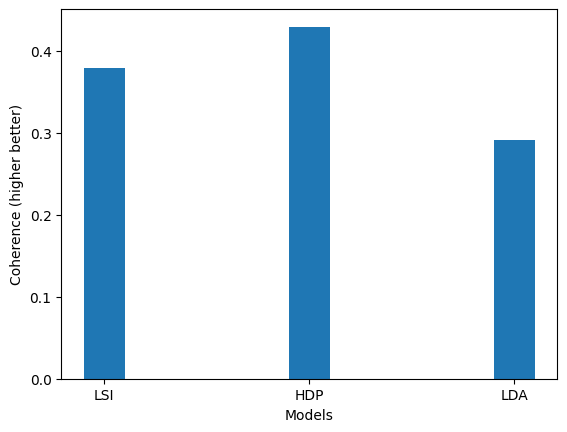

In [13]:
evaluate_bar_graph([lsi_coherence, hdp_coherence, lda_coherence],
                   ['LSI', 'HDP', 'LDA'], y_title='Coherence (higher better)')

-8.928160048583829
-115.51567261827833


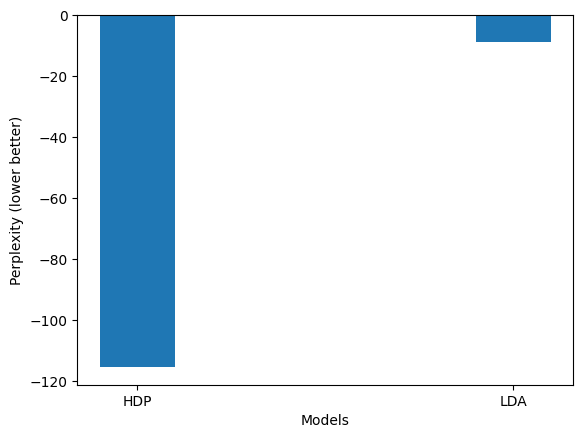

In [14]:
lda_ppl = ldamodel.log_perplexity(corpus)

# you can rewrite HDP as a LDA model:
hdpldam = hdpmodel.suggested_lda_model()
hdp_ppl = hdpldam.log_perplexity(corpus)

print(lda_ppl)
print(hdp_ppl)

evaluate_bar_graph([hdp_ppl, lda_ppl], ['HDP', 'LDA'], y_title='Perplexity (lower better)')

[[(0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (5, 1), (6, 1), (7, 2), (8, 1), (9, 1), (10, 2), (11, 3), (12, 2), (13, 1), (14, 1), (15, 1), (16, 1), (17, 1), (18, 4), (19, 1), (20, 1), (21, 1), (22, 1), (23, 3), (24, 1), (25, 4), (26, 1), (27, 2), (28, 1), (29, 2), (30, 1), (31, 2), (32, 1), (33, 1), (34, 1), (35, 1), (36, 1), (37, 1), (38, 1), (39, 1), (40, 1), (41, 1), (42, 1), (43, 1), (44, 1), (45, 1), (46, 1), (47, 2), (48, 1), (49, 1), (50, 1), (51, 1), (52, 1), (53, 3), (54, 1), (55, 1), (56, 5), (57, 2), (58, 1), (59, 3), (60, 1), (61, 1), (62, 1), (63, 1), (64, 1), (65, 3), (66, 1), (67, 1), (68, 1), (69, 1), (70, 1), (71, 1), (72, 1), (73, 2), (74, 1), (75, 1), (76, 1), (77, 3), (78, 1), (79, 1), (80, 1), (81, 1), (82, 2), (83, 1), (84, 1), (85, 2), (86, 1), (87, 3), (88, 1), (89, 1), (90, 1), (91, 1), (92, 1), (93, 1), (94, 1), (95, 1), (96, 1), (97, 1), (98, 1), (99, 1), (100, 1), (101, 1), (102, 1), (103, 1), (104, 1), (105, 1), (106, 1), (107, 1), (108, 2)], [(71, 1), (83, 1)

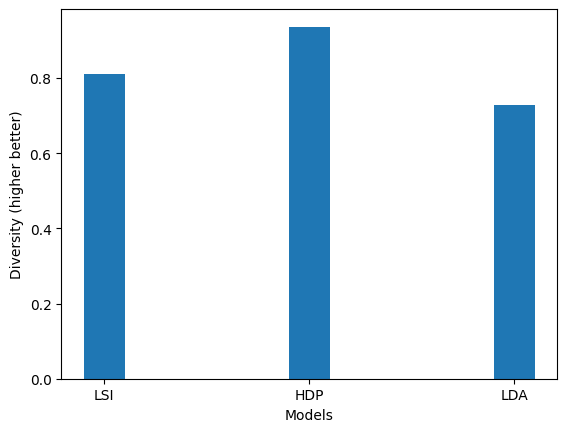

In [15]:
lsitopics = [topic for topicid, topic in lsimodel.show_topics(formatted=False)]
hdptopics = [topic for topicid, topic in hdpmodel.show_topics(formatted=False)]
ldatopics = [topic for topicid, topic in ldamodel.show_topics(formatted=False)]

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

ntexts = [' '.join(text) for text in texts]

vectorizer = TfidfVectorizer(
    max_features=None, stop_words="english"
)
print(corpus)
print(ntexts)
vectorizer.fit(ntexts)
print()


divesities = []
models = [lsimodel, hdpmodel, ldamodel]
for model in models:
  print('-' * 50)
  topics = [' '.join([t[0] for t in topic]) for topicid, topic in model.show_topics(formatted=False)]
  topics = [vectorizer.transform([topic]).toarray() for topic in topics]
  topics_matrix = np.concatenate(topics, axis=0)
  similarities = cosine_similarity(topics_matrix)
  topic_diversity = 1 - np.mean(similarities)
  print(f"Topic Diversity: {topic_diversity}")
  divesities.append(topic_diversity)

evaluate_bar_graph(divesities, ['LSI', 'HDP', 'LDA'], y_title='Diversity (higher better)')

# More Topic Modeling on sklearn

Here we follow [this tutorial](https://scikit-learn.org/1.5/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html#sphx-glr-auto-examples-applications-plot-topics-extraction-with-nmf-lda-py). The default parameters (n_samples / n_features / n_components) should make the example runnable in a couple of tens of seconds. You can try to increase the dimensions of the problem, but be aware that the time complexity is polynomial in NMF. In LDA, the time complexity is proportional to (n_samples * iterations).

In [16]:
from time import time

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import NMF, LatentDirichletAllocation, MiniBatchNMF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

n_samples = 2000
n_features = 1000
n_components = 10
n_top_words = 20
batch_size = 128
init = "nndsvda"

In [17]:
def plot_top_words(model, feature_names, n_top_words, title):
    fig, axes = plt.subplots(2, 5, figsize=(30, 15), sharex=True)
    axes = axes.flatten()

    cosine_sim_matrix = cosine_similarity(model.components_)
    topic_diversity = 1 - np.mean(np.max(cosine_sim_matrix, axis=1))
    print(f"Topic Diversity: {topic_diversity}")
    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[-n_top_words:]
        top_features = feature_names[top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f"Topic {topic_idx +1}", fontdict={"fontsize": 30})
        ax.tick_params(axis="both", which="major", labelsize=20)
        for i in "top right left".split():
            ax.spines[i].set_visible(False)
        fig.suptitle(title, fontsize=40)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

Load the 20 newsgroups dataset and vectorize it. We use a few heuristics
 to filter out useless terms early on: the posts are stripped of headers,
 footers and quoted replies, and common English words, words occurring in
 only one document or in at least 95% of the documents are removed.

In [18]:
print("Loading dataset...")
t0 = time()
data, _ = fetch_20newsgroups(
    shuffle=True,
    random_state=1,
    remove=("headers", "footers", "quotes"),
    return_X_y=True,
)
data_samples = data[:n_samples]
print("done in %0.3fs." % (time() - t0))

# Use tf-idf features for NMF.
print("Extracting tf-idf features for NMF...")
tfidf_vectorizer = TfidfVectorizer(
    max_df=0.95, min_df=2, max_features=n_features, stop_words="english"
)
t0 = time()
tfidf = tfidf_vectorizer.fit_transform(data_samples)
print("done in %0.3fs." % (time() - t0))

# Use tf (raw term count) features for LDA.
print("Extracting tf features for LDA...")
tf_vectorizer = CountVectorizer(
    max_df=0.95, min_df=2, max_features=n_features, stop_words="english"
)
t0 = time()
tf = tf_vectorizer.fit_transform(data_samples)
print("done in %0.3fs." % (time() - t0))
print()

Loading dataset...
done in 9.716s.
Extracting tf-idf features for NMF...
done in 0.182s.
Extracting tf features for LDA...
done in 0.207s.



## Non-Negative Matrix Factorization

Non-negative Matrix Factorization is applied with two different objective functions: the Frobenius norm, and the generalized Kullback-Leibler divergence. The latter is equivalent to Probabilistic Latent Semantic Indexing. NMF can be thought of as similar to the LSA/LDA we've done before, but more interpretable as there can be no negative numbers (what does it mean to say a document contains a topic of "-5 politics"?)
https://en.wikipedia.org/wiki/Non-negative_matrix_factorization

NMF is a bit more interpretable because the formula is just $$V = WH$$ where V is an m\*n matrix, W is a m\*p matrix and H is a p\*n matrix. This is demonstrated in a really cool visual way in Lee and Seung's 1999 paper available here https://pubmed.ncbi.nlm.nih.gov/10548103/ , where we see that W has learned a bunch of building blocks of the data!



Fitting the NMF model (Frobenius norm) with tf-idf features, n_samples=2000 and n_features=1000...
done in 0.093s.
Topic Diversity: 2.220446049250313e-16


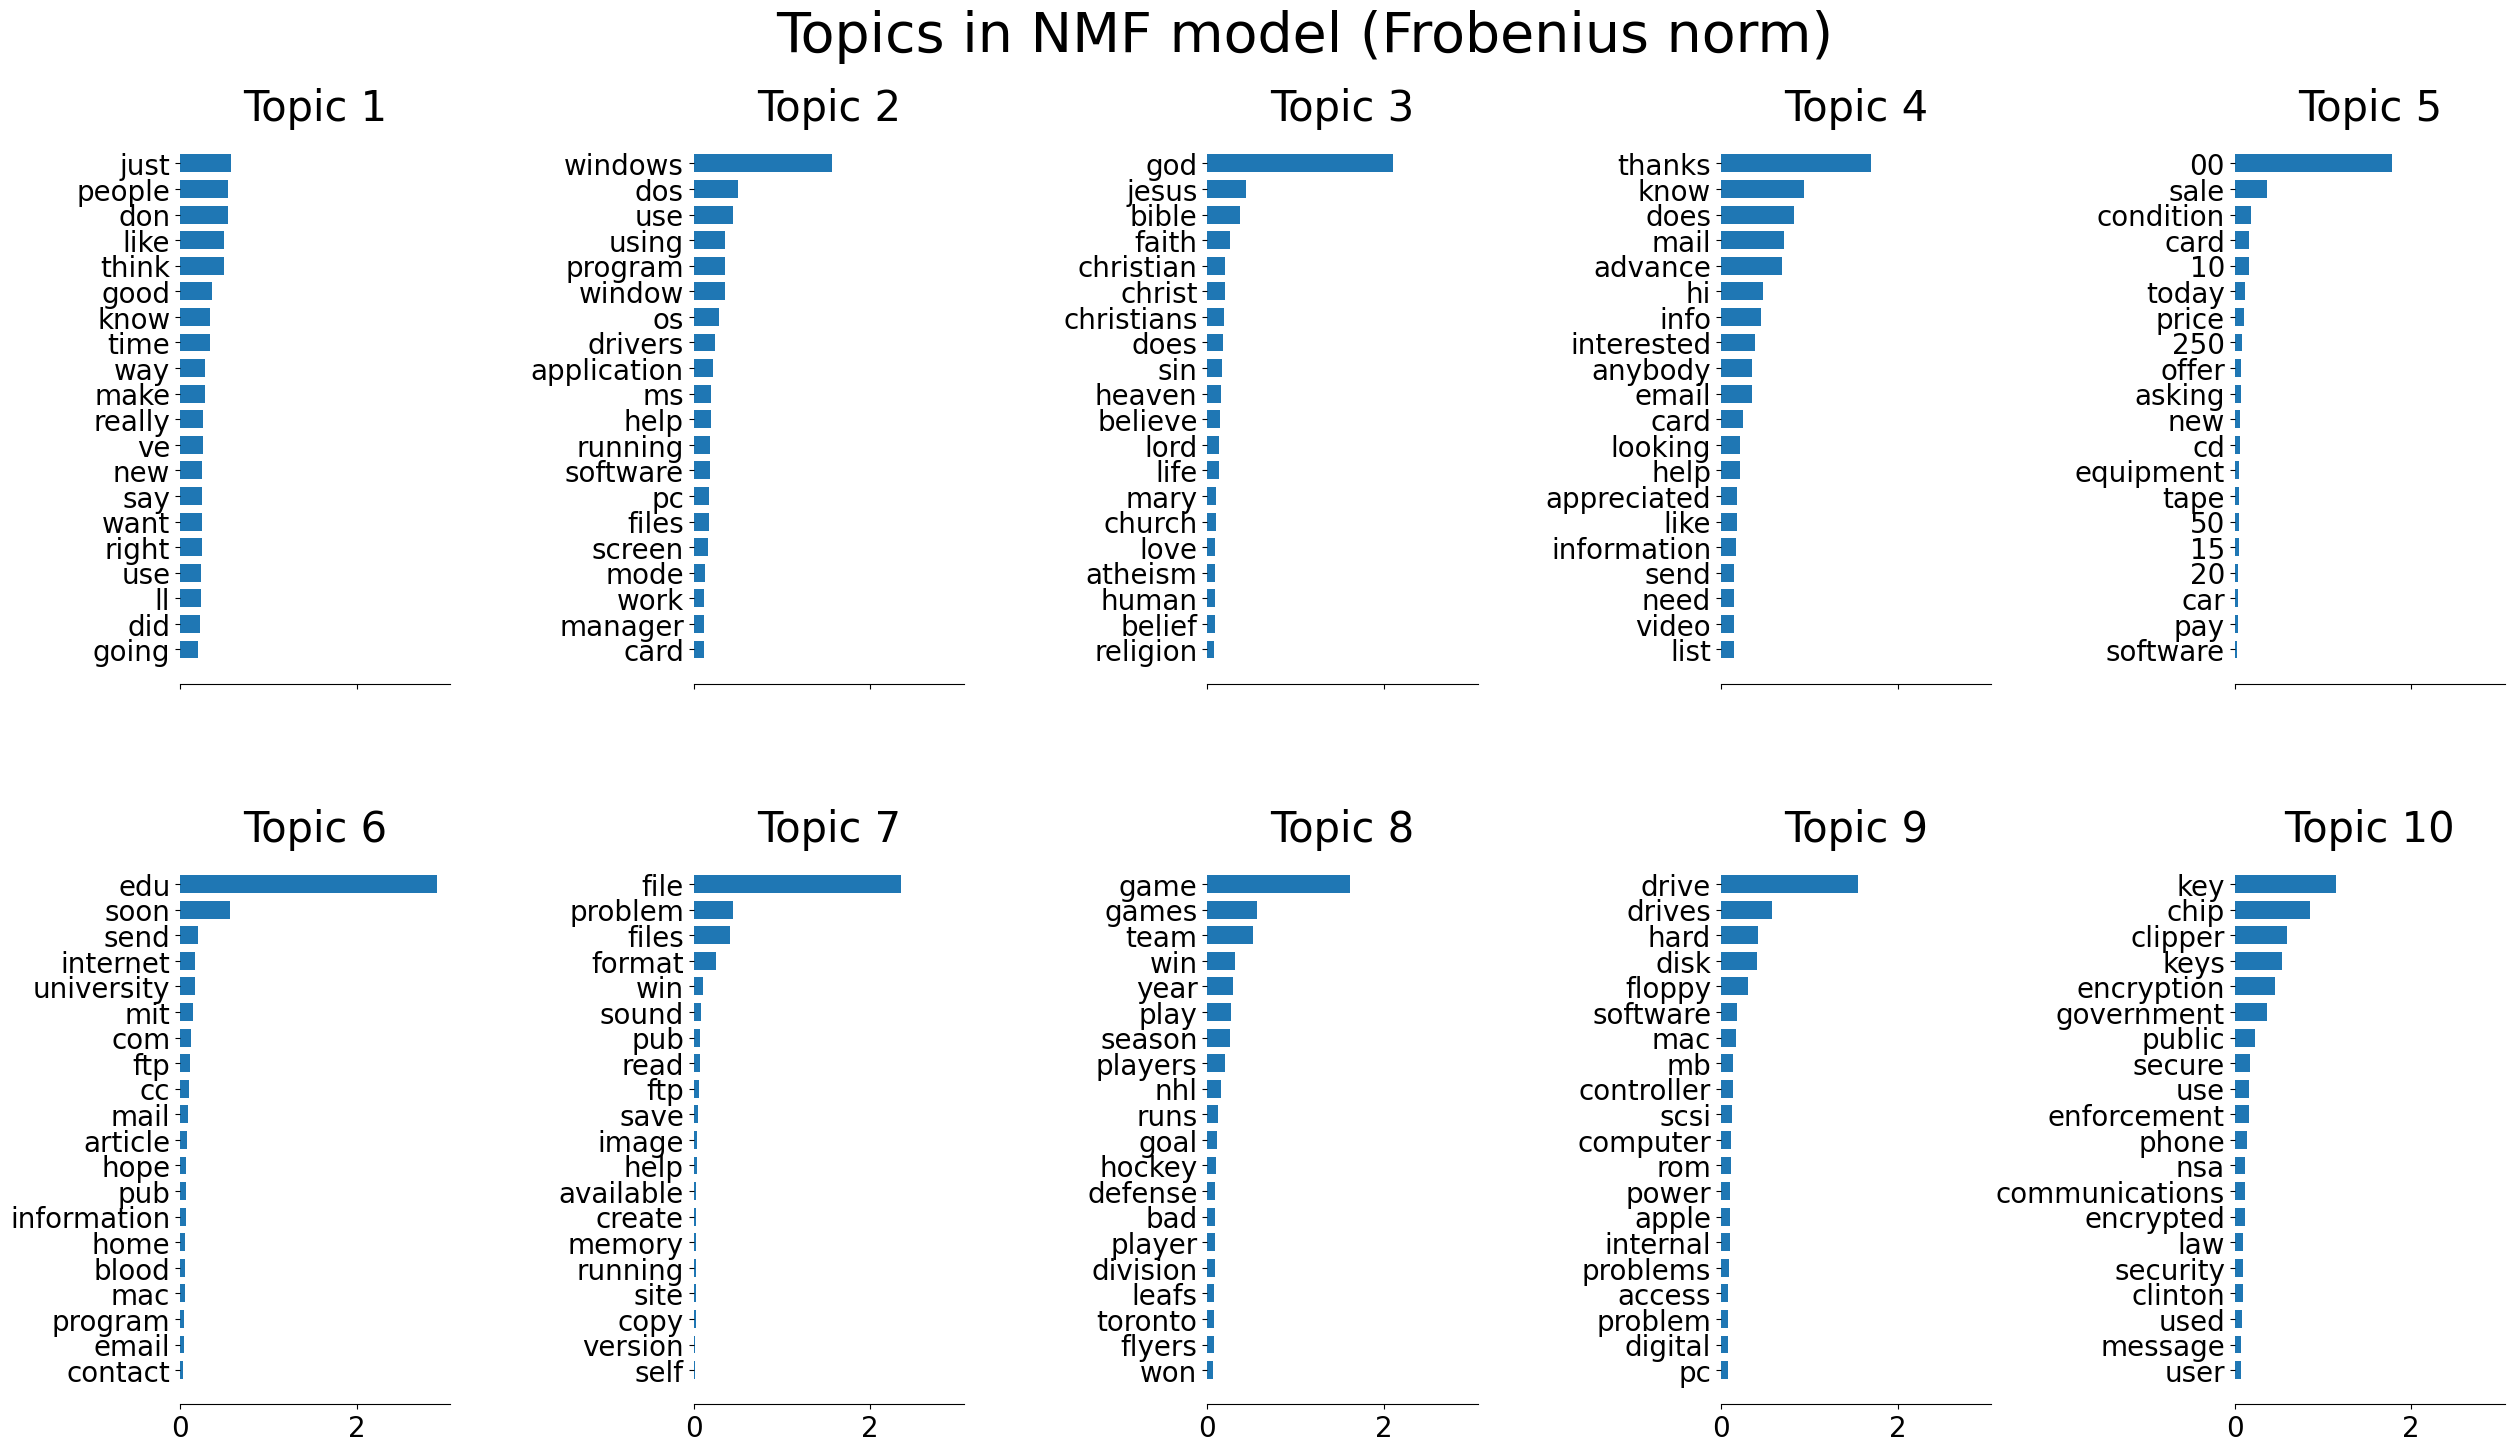

In [19]:
# Fit the NMF model
print(
    "Fitting the NMF model (Frobenius norm) with tf-idf features, "
    "n_samples=%d and n_features=%d..." % (n_samples, n_features)
)
t0 = time()
nmf = NMF(
    n_components=n_components,
    random_state=1,
    init=init,
    beta_loss="frobenius",
    alpha_W=0.00005,
    alpha_H=0.00005,
    l1_ratio=1,
).fit(tfidf)
print("done in %0.3fs." % (time() - t0))

tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()
plot_top_words(
    nmf, tfidf_feature_names, n_top_words, "Topics in NMF model (Frobenius norm)"
)



 Fitting the NMF model (generalized Kullback-Leibler divergence) with tf-idf features, n_samples=2000 and n_features=1000...
done in 1.739s.
Topic Diversity: 0.0


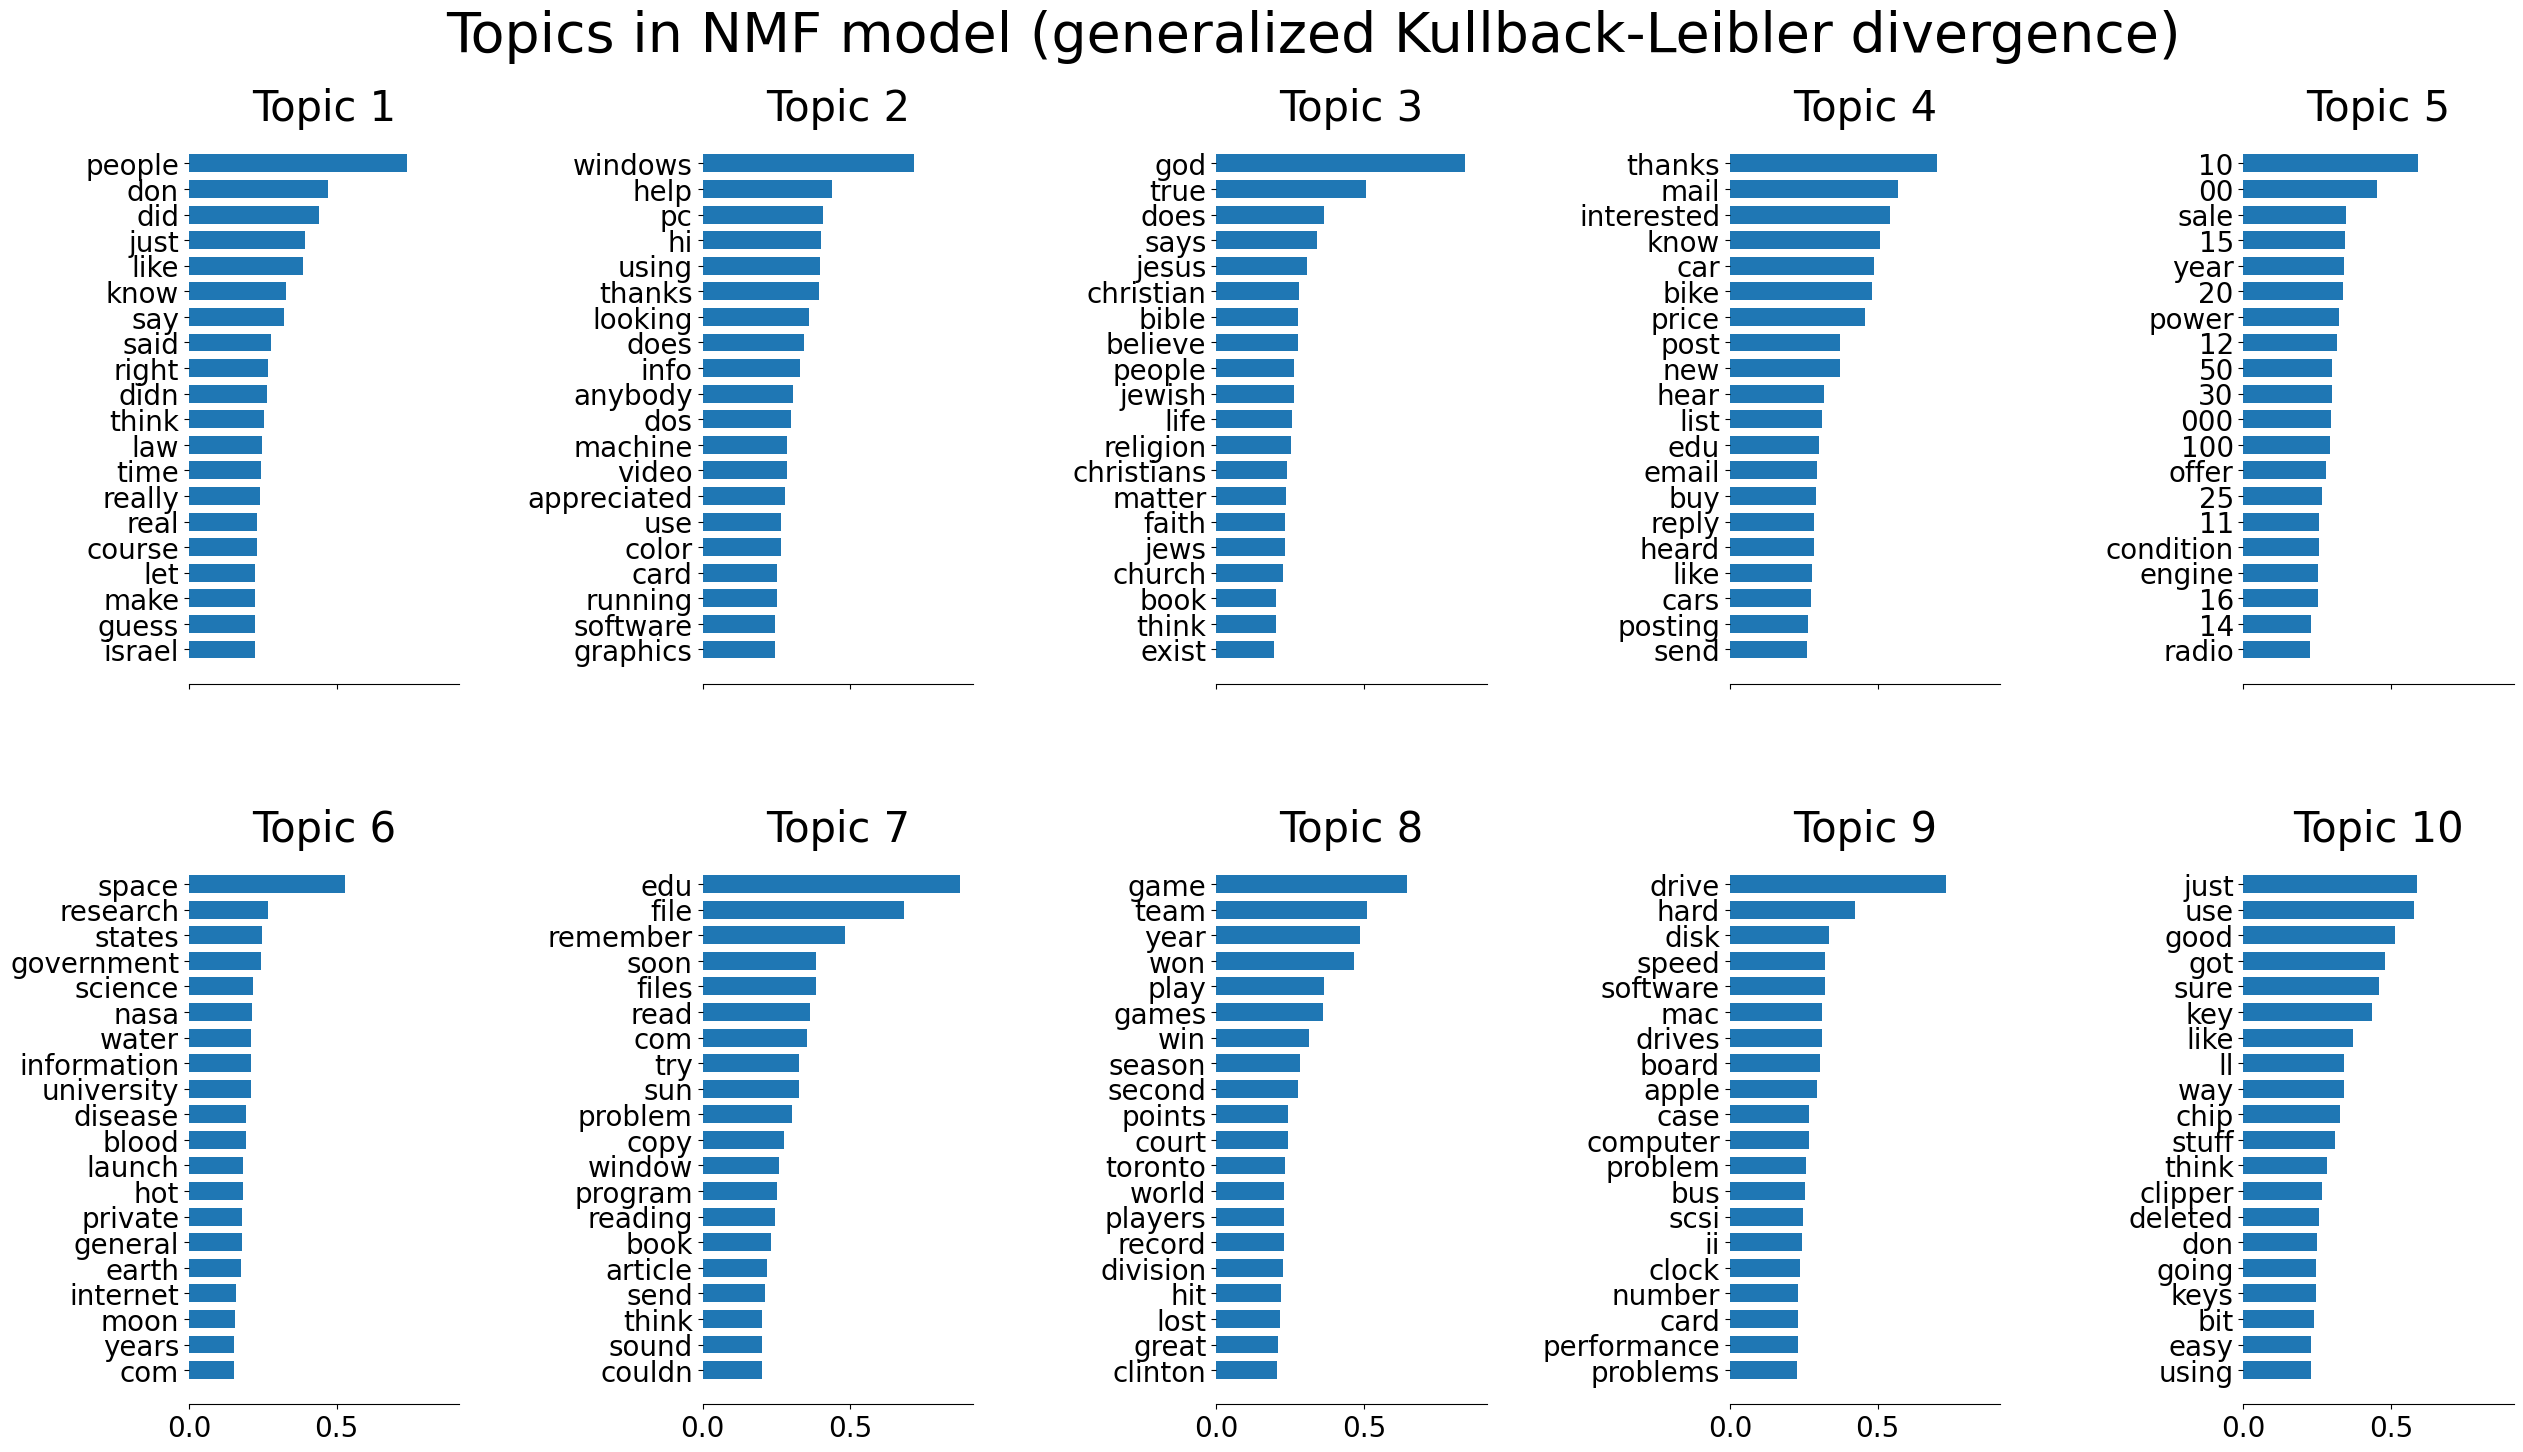

In [20]:
# Fit the NMF model
print(
    "\n" * 2,
    "Fitting the NMF model (generalized Kullback-Leibler "
    "divergence) with tf-idf features, n_samples=%d and n_features=%d..."
    % (n_samples, n_features),
)
t0 = time()
nmf = NMF(
    n_components=n_components,
    random_state=1,
    init=init,
    beta_loss="kullback-leibler",
    solver="mu",
    max_iter=1000,
    alpha_W=0.00005,
    alpha_H=0.00005,
    l1_ratio=0.5,
).fit(tfidf)
print("done in %0.3fs." % (time() - t0))

tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()
plot_top_words(
    nmf,
    tfidf_feature_names,
    n_top_words,
    "Topics in NMF model (generalized Kullback-Leibler divergence)",
)



 Fitting LDA models with tf features, n_samples=2000 and n_features=1000...
done in 6.289s.
Topic Diversity: 3.3306690738754696e-16


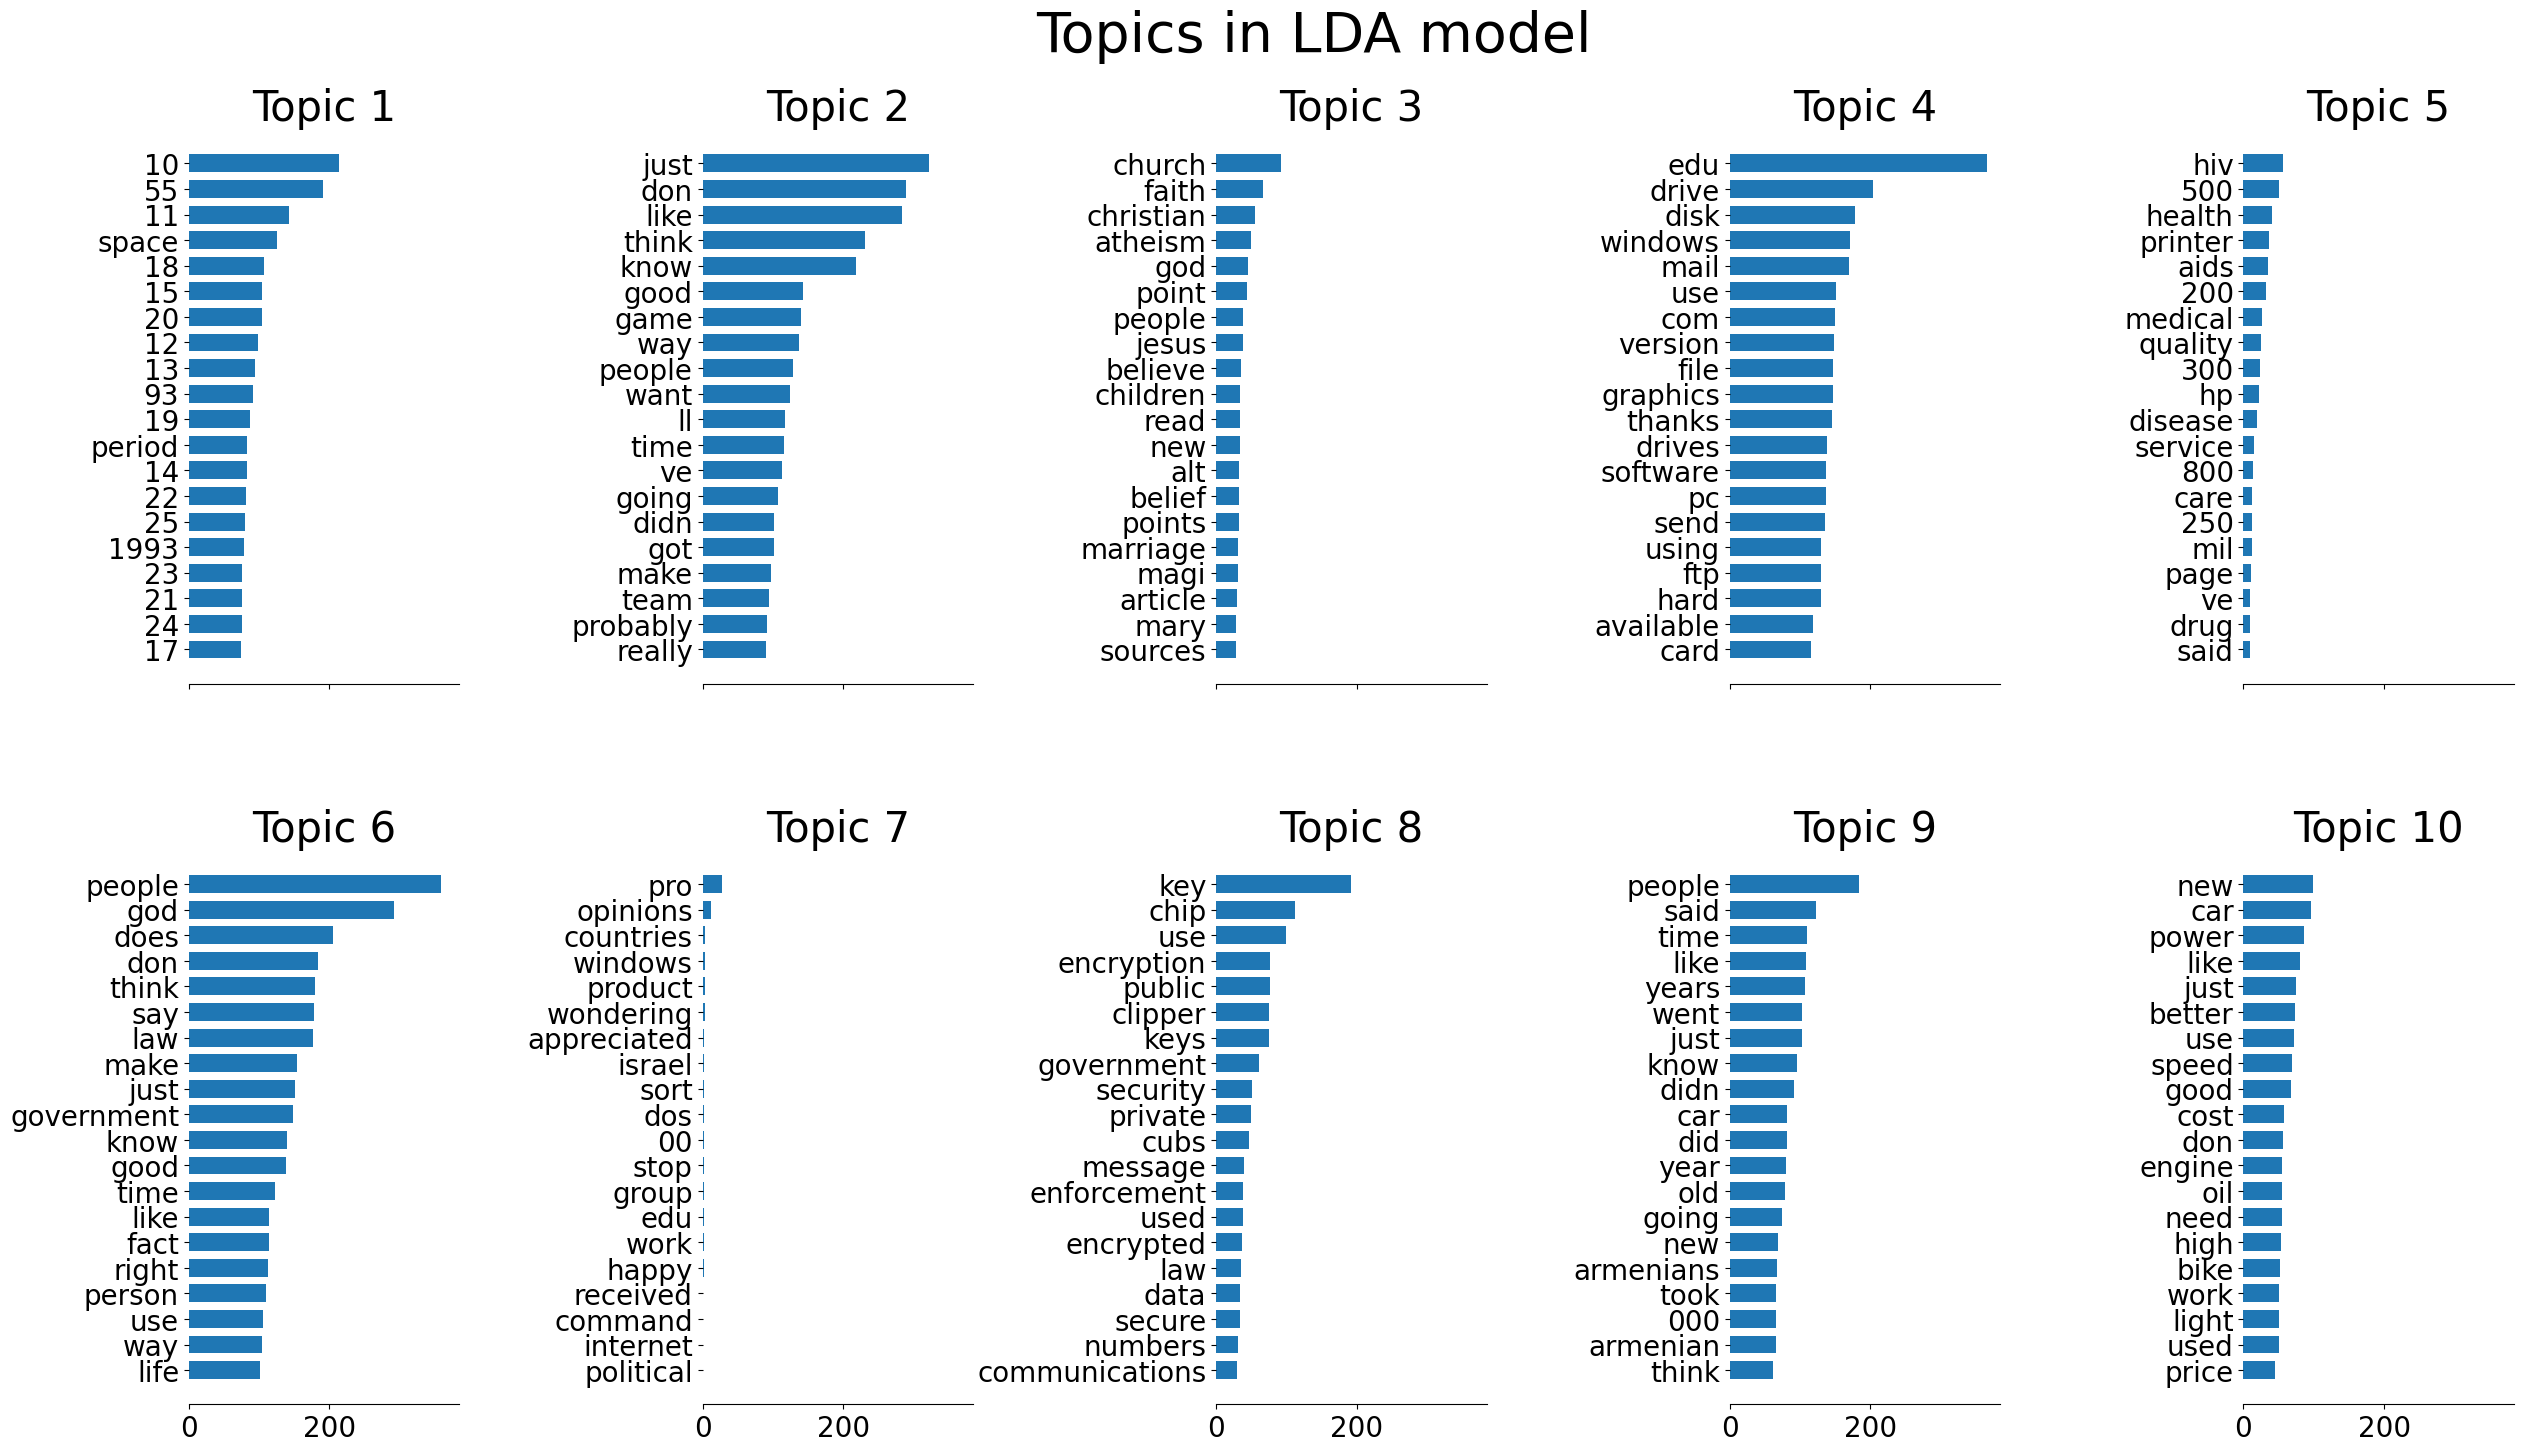

In [21]:
print(
    "\n" * 2,
    "Fitting LDA models with tf features, n_samples=%d and n_features=%d..."
    % (n_samples, n_features),
)
lda = LatentDirichletAllocation(
    n_components=n_components,
    max_iter=5,
    learning_method="online",
    learning_offset=50.0,
    random_state=0,
)
t0 = time()
lda.fit(tf)
print("done in %0.3fs." % (time() - t0))

tf_feature_names = tf_vectorizer.get_feature_names_out()
plot_top_words(lda, tf_feature_names, n_top_words, "Topics in LDA model")

# BERT Topic Modeling

With the rise of transformer-based models like BERT (Bidirectional Encoder Representations from Transformers), topic modeling has taken a leap forward in accuracy and interpretability.

### Why Use BERT for Topic Modeling?
- **Contextual Understanding:** BERT captures the semantic meaning of words in their context, unlike traditional approaches that treat words independently.
- **Rich Representations:** Pre-trained embeddings from BERT encode deep semantic relationships between words and sentences, which improve the clustering of similar topics.
- **Handles Ambiguity:** BERT excels at differentiating word meanings based on context, which is a challenge for traditional topic modeling.

In [22]:
!pip install -q bertopic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.0/153.0 kB 4.9 MB/s eta 0:00:00


In [23]:
from sklearn.datasets import fetch_20newsgroups
from bertopic import BERTopic

In [24]:
docs = fetch_20newsgroups(subset='all',  remove=('headers', 'footers', 'quotes'))['data']

# EXERCISE: for the brave, run BERTTopic on the full dataset on a Colab's GPU
docs = docs[:1000]

In [25]:
topic_model = BERTopic(language='english', calculate_probabilities=True, verbose=True)
topics, probs = topic_model.fit_transform(docs)

2025-12-02 12:46:52,908 - BERTopic - Embedding - Transforming documents to embeddings.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

2025-12-02 12:48:03,924 - BERTopic - Embedding - Completed ✓
2025-12-02 12:48:03,926 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2025-12-02 12:48:12,405 - BERTopic - Dimensionality - Completed ✓
2025-12-02 12:48:12,407 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-12-02 12:48:12,460 - BERTopic - Cluster - Completed ✓
2025-12-02 12:48:12,464 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-12-02 12:48:12,601 - BERTopic - Representation - Completed ✓


In [26]:
freq = topic_model.get_topic_info()

freq

,Topic,Count,Name,Representation,Representative_Docs
0,0,874,0_the_to_of_and,"[the, to, of, and, is, in, that, it, for, you]",[\n\nPaul's statement only asserts that that p...
1,1,94,1_the_to_in_and,"[the, to, in, and, he, of, that, is, but, was]",[\nRight. Most definitely.\n\n\nThis may be t...
2,2,32,2_testing_deletion_hello_was,"[testing, deletion, hello, was, , , , , , ]","[was...\n, \n(Deletion)\n , hello testing\n\n\n]"


In [27]:
topic_model.get_topic(0)

[('the', np.float64(0.11117194494704717)),
 ('to', np.float64(0.07274418175635815)),
 ('of', np.float64(0.07005572846485006)),
 ('and', np.float64(0.06093849653285045)),
 ('is', np.float64(0.0495786291608951)),
 ('in', np.float64(0.04901601677916724)),
 ('that', np.float64(0.04896805908356343)),
 ('it', np.float64(0.03904946414097187)),
 ('for', np.float64(0.03645184624330992)),
 ('you', np.float64(0.0341782791101751))]

In [28]:
topic_model.visualize_topics()

TypeError: Cannot use scipy.linalg.eigh for sparse A with k >= N. Use scipy.linalg.eigh(A.toarray()) or reduce k.

In [29]:
topic_model.visualize_barchart(top_n_topics=5)

In [30]:
similar_topics, similarity = topic_model.find_topics("vehicle", top_n=5)

for i, sim in enumerate(similar_topics):
    print(similar_topics[i], similarity[i])

2 0.32882795
0 0.14134175
1 -0.073844194


In [31]:
topic_model.get_topic(5)

False

## Custom Model

In [32]:
from sentence_transformers import SentenceTransformer

In [39]:
# EXERCISE: choose your favorite pretrained model

from sklearn.feature_extraction.text import CountVectorizer

#sentence_model = SentenceTransformer('distilbert-base-nli-mean-tokens', device="cpu")
vectorizer_model = CountVectorizer(stop_words="english")

topic_model = BERTopic(vectorizer_model=vectorizer_model, verbose=True)

topics, probs = topic_model.fit_transform(docs)

2025-12-02 13:20:44,069 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

2025-12-02 13:21:57,313 - BERTopic - Embedding - Completed ✓
2025-12-02 13:21:57,314 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2025-12-02 13:21:59,410 - BERTopic - Dimensionality - Completed ✓
2025-12-02 13:21:59,412 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-12-02 13:21:59,440 - BERTopic - Cluster - Completed ✓
2025-12-02 13:21:59,444 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-12-02 13:21:59,658 - BERTopic - Representation - Completed ✓


In [40]:
topic_model.visualize_barchart(top_n_topics=5)

In [36]:
topic_model.visualize_topics()

ValueError: zero-size array to reduction operation maximum which has no identity